Saving plots to: /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/plots
Reading power logs from: /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/power_logs/llama_3b
Saving plots to: /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/plots/llama_3b
tp1_pp1_dp4: avg=583.8W  steady_avg=670.4W  peak=1199.7W  samples=748
tp4_pp1_dp1: avg=645.3W  steady_avg=754.0W  peak=841.4W  samples=582
tp1_pp4_dp1: avg=649.0W  steady_avg=761.8W  peak=986.2W  samples=494
tp2_pp2_dp1: avg=697.5W  steady_avg=823.5W  peak=1013.4W  samples=473
tp2_pp1_dp2: avg=652.9W  steady_avg=762.0W  peak=984.5W  samples=594
tp1_pp2_dp2: avg=626.7W  steady_avg=729.5W  peak=1059.2W  samples=575


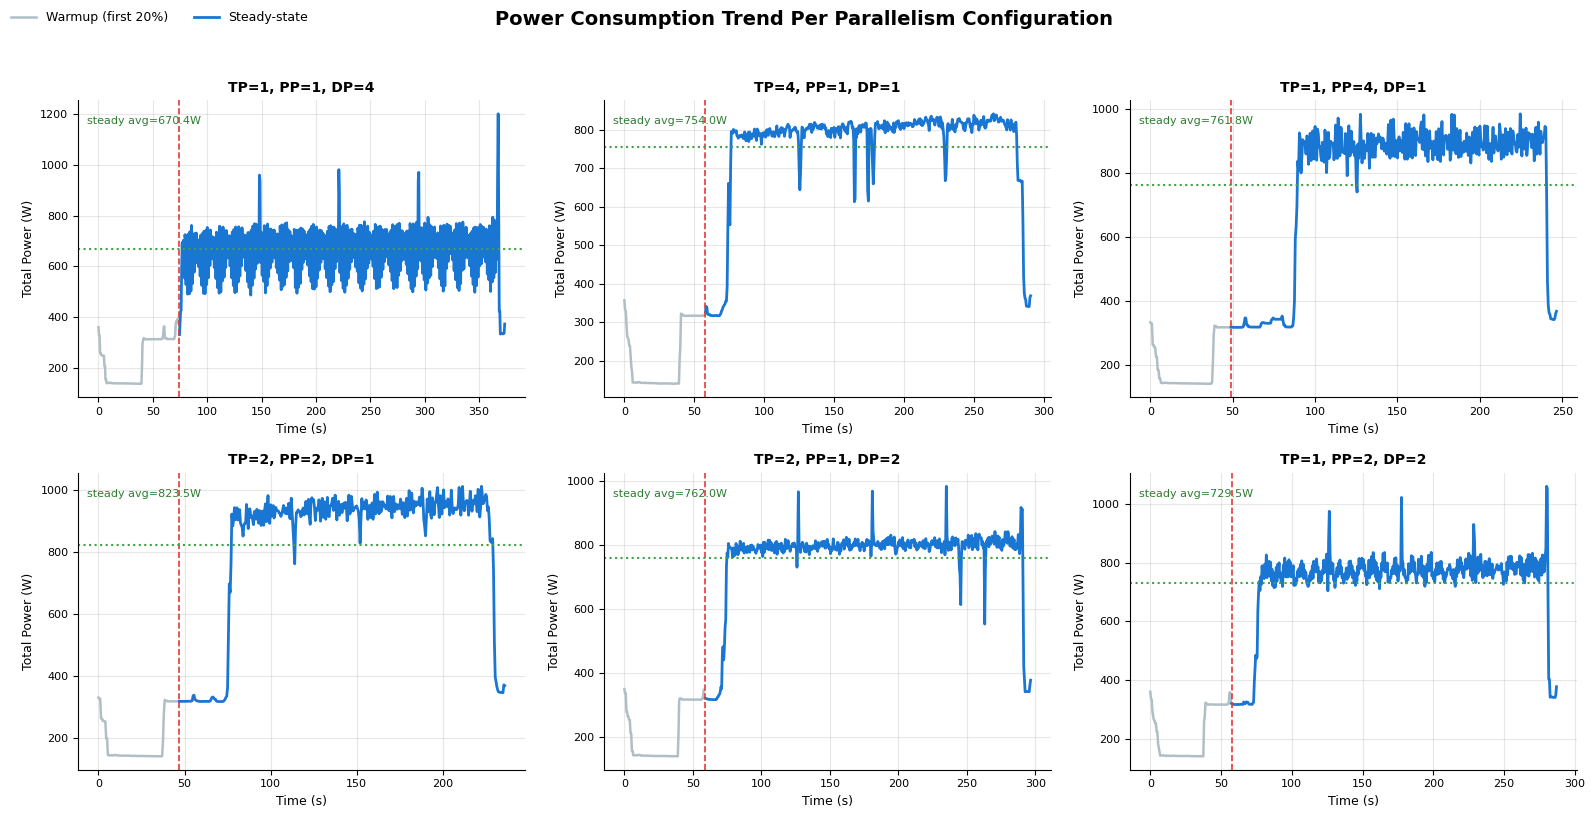

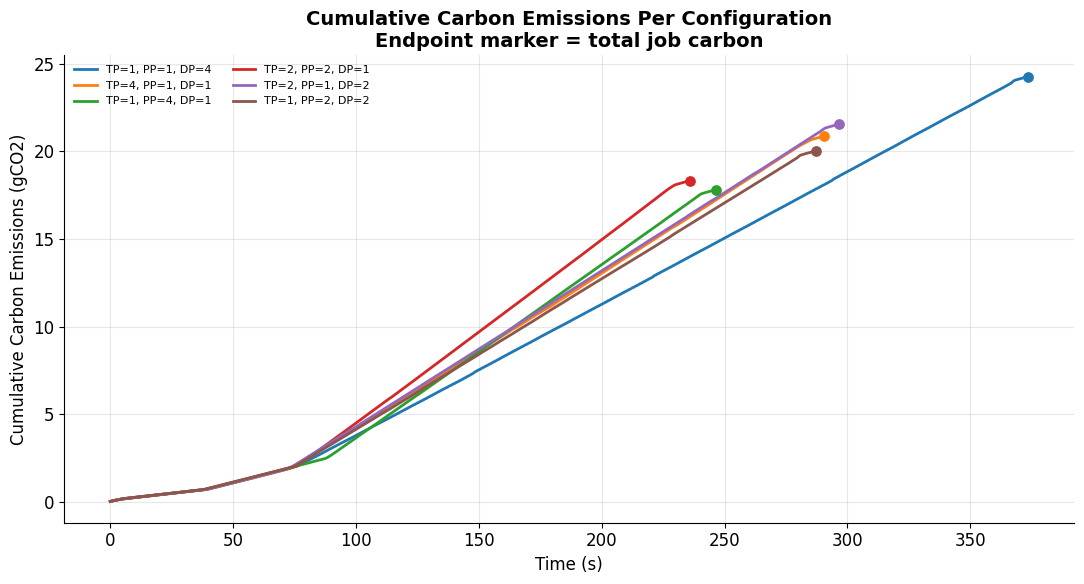

DP=4
(TP=1,PP=1)          |  374.0s |  583.8W |   60.65Wh |  24.26gCO₂ |   2190.4 tok/s
TP=4
(PP=1,DP=1)          |  291.0s |  645.3W |   52.16Wh |  20.87gCO₂ |   2815.1 tok/s
PP=4
(TP=1,DP=1)          |  247.0s |  649.0W |   44.53Wh |  17.81gCO₂ |   3316.6 tok/s
TP=2,PP=2
(DP=1)          |  236.5s |  697.5W |   45.82Wh |  18.33gCO₂ |   3463.8 tok/s
TP=2,DP=2
(PP=1)          |  297.0s |  652.9W |   53.86Wh |  21.55gCO₂ |   2758.2 tok/s
PP=2,DP=2
(TP=1)          |  287.5s |  626.7W |   50.05Wh |  20.02gCO₂ |   2849.4 tok/s


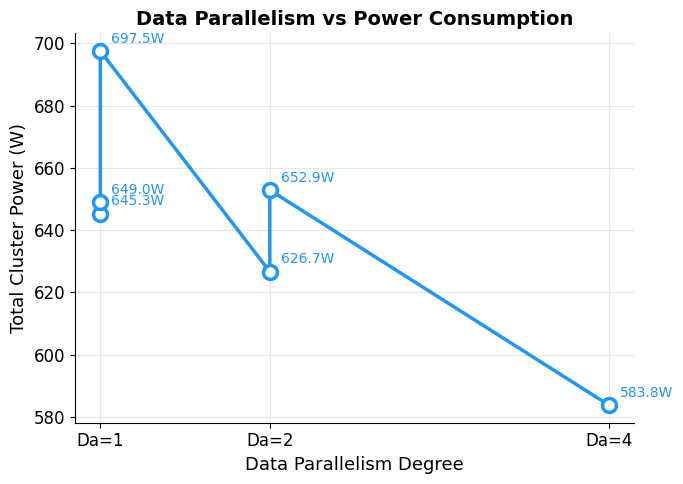

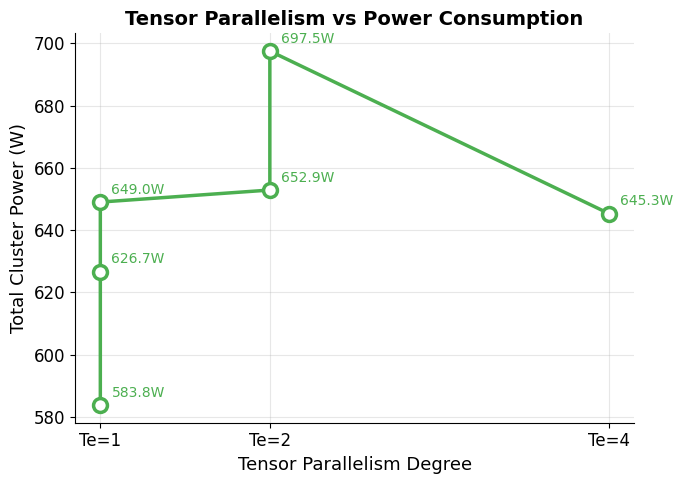

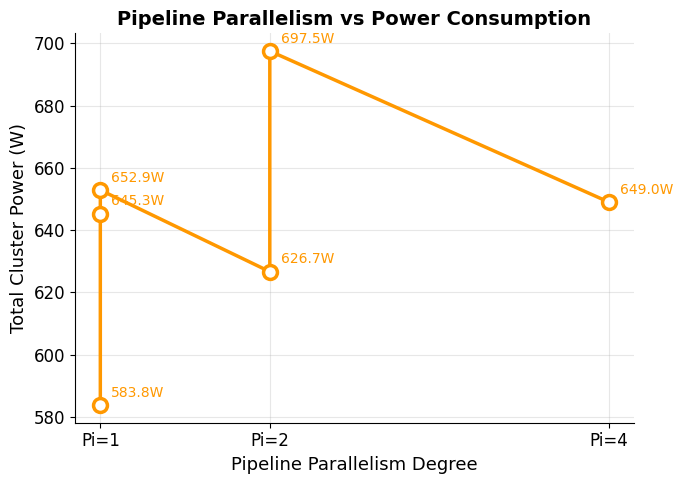

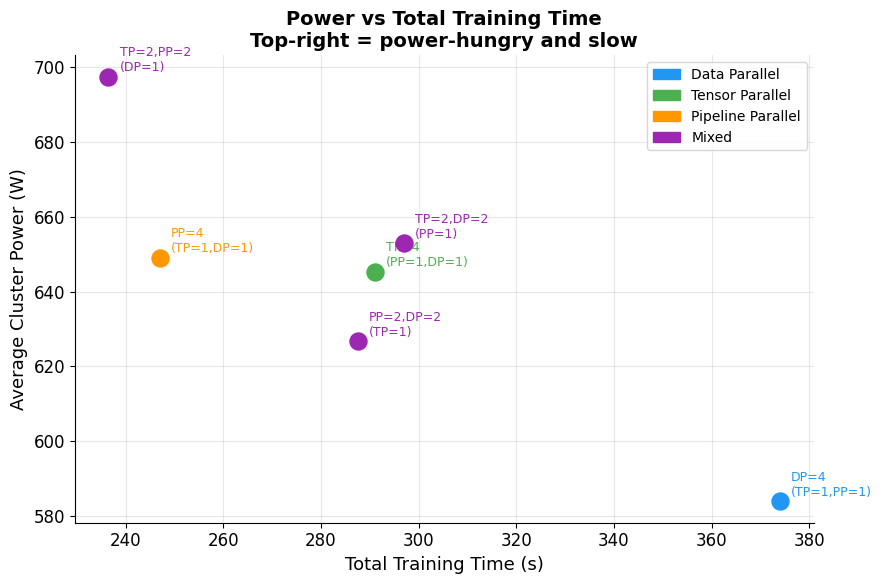

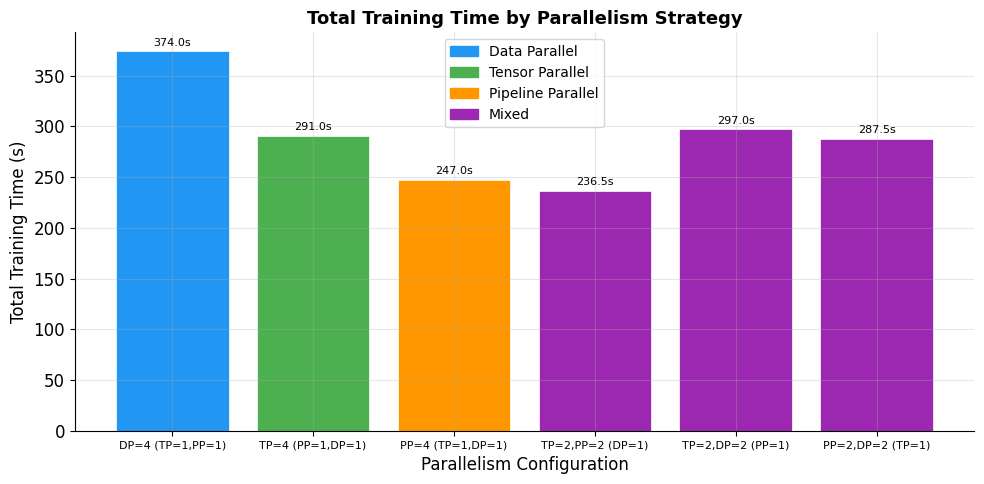

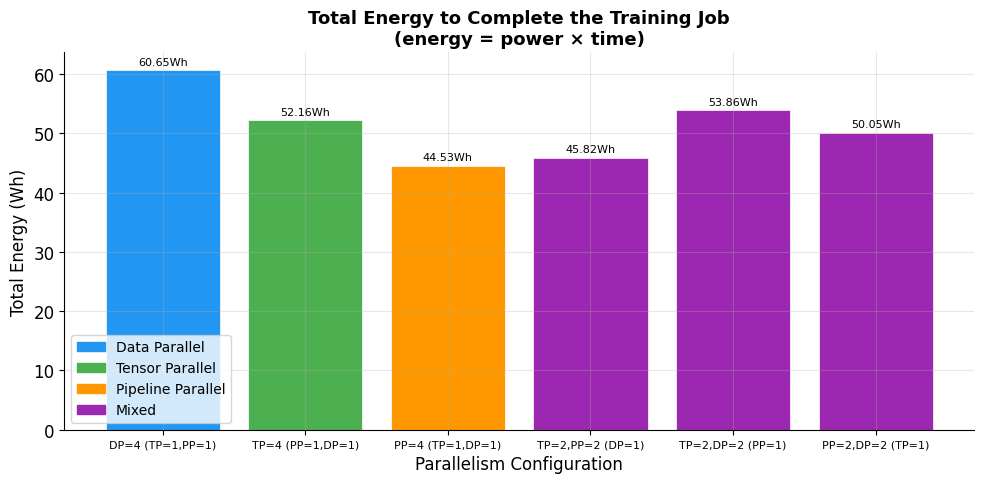

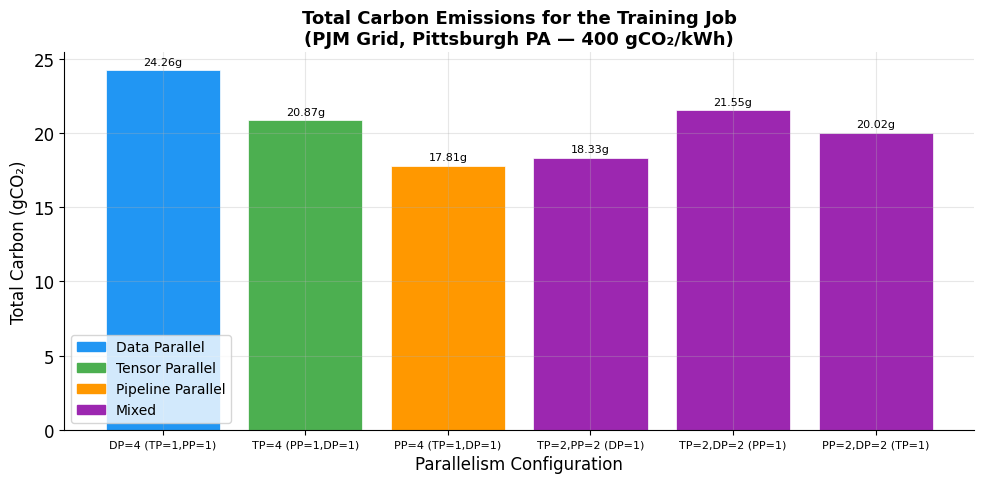

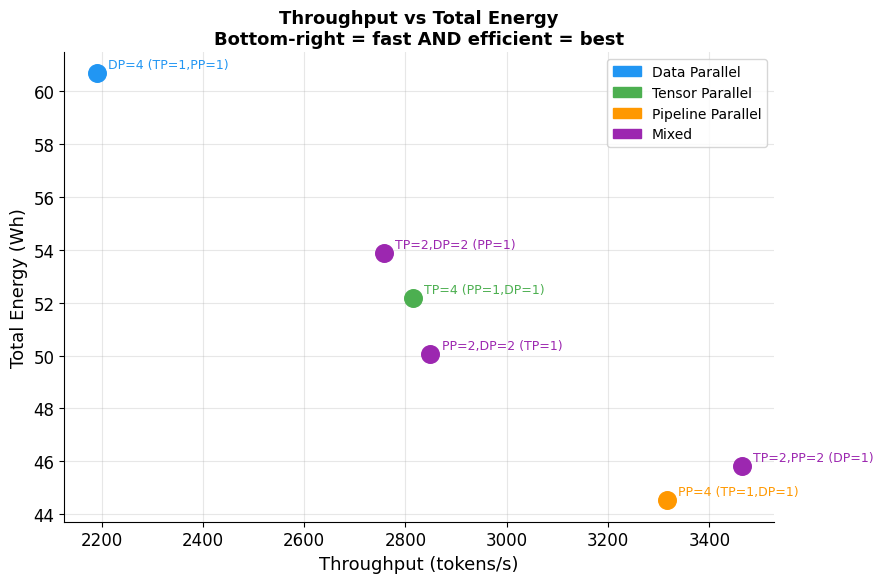

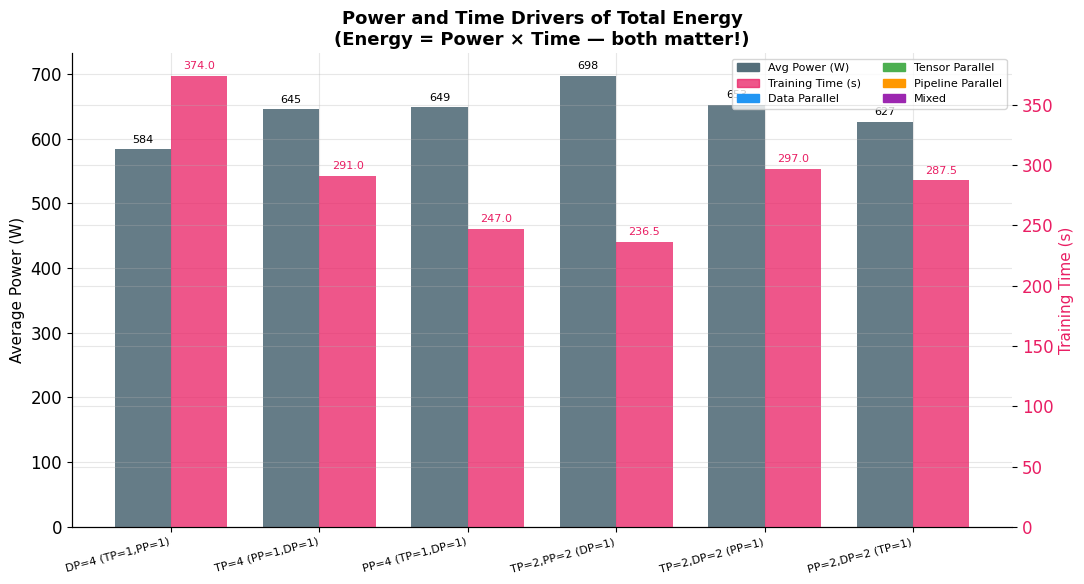

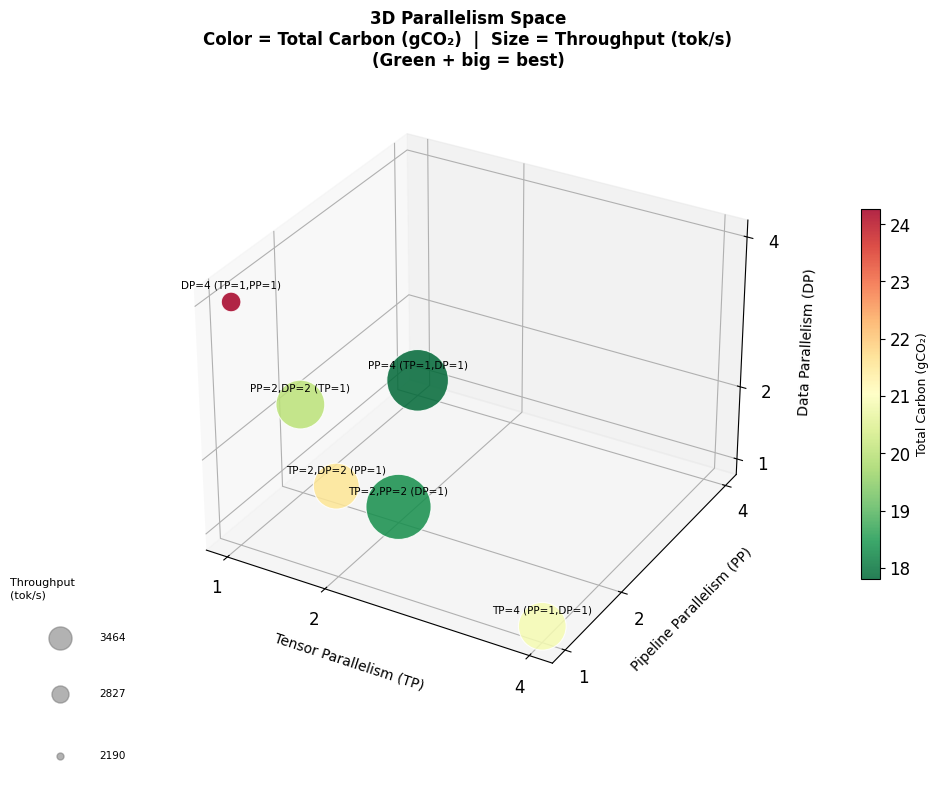

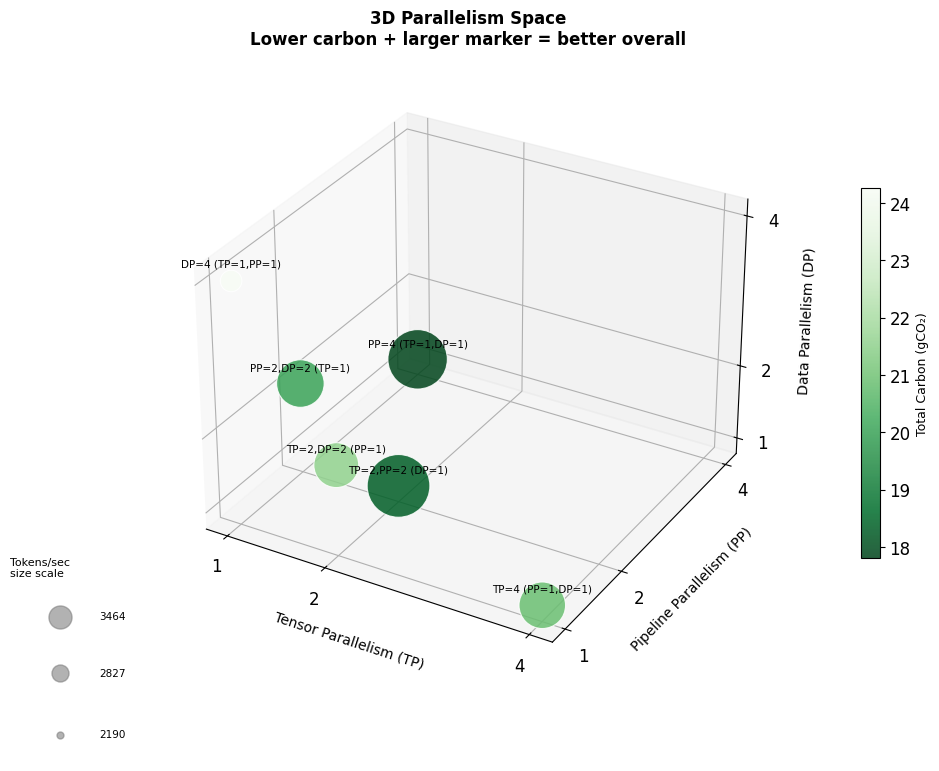

In [3]:
# Visualization Notebook
#
# This notebook analyzes power logs from 3D parallelism benchmarks.
# Key insight: for a fixed training job, what matters is TOTAL energy
# and carbon (energy = power × time), not per-token rates.
#
# Configs whose CSV is missing or empty are automatically skipped.

# =====================================================================
# 1) Imports and Plot Style
# =====================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.cm as cm

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

COLORS = {
    "dp": "#2196F3",
    "tp": "#4CAF50",
    "pp": "#FF9800",
    "mixed": "#9C27B0",
}
PLOTS_DIR = os.path.join(os.getcwd(), "plots")
os.makedirs(PLOTS_DIR, exist_ok=True)
print(f"Saving plots to: {PLOTS_DIR}")

# =====================================================================
# 2) Load CSVs and Compute Power Statistics
# =====================================================================
BASE = os.getcwd()
MODEL_NAME = "llama_3b"
DATA_DIR = os.path.join(BASE, "power_logs", MODEL_NAME)
PLOTS_DIR = os.path.join(BASE, "plots", MODEL_NAME)
os.makedirs(PLOTS_DIR, exist_ok=True)
print(f"Reading power logs from: {DATA_DIR}")
print(f"Saving plots to: {PLOTS_DIR}")

all_possible_configs = {
    "tp1_pp1_dp4": {"tp": 1, "pp": 1, "dp": 4, "file": "tp1_pp1_dp4_power.csv"},
    "tp4_pp1_dp1": {"tp": 4, "pp": 1, "dp": 1, "file": "tp4_pp1_dp1_power.csv"},
    "tp1_pp4_dp1": {"tp": 1, "pp": 4, "dp": 1, "file": "tp1_pp4_dp1_power.csv"},
    "tp2_pp2_dp1": {"tp": 2, "pp": 2, "dp": 1, "file": "tp2_pp2_dp1_power.csv"},
    "tp2_pp1_dp2": {"tp": 2, "pp": 1, "dp": 2, "file": "tp2_pp1_dp2_power.csv"},
    "tp1_pp2_dp2": {"tp": 1, "pp": 2, "dp": 2, "file": "tp1_pp2_dp2_power.csv"},
}

# Only keep configs whose CSV exists and has data
configs = {}
skipped = []
for name, cfg in all_possible_configs.items():
    path = os.path.join(DATA_DIR, cfg["file"])
    if not os.path.exists(path):
        skipped.append(name)
        continue
    df = pd.read_csv(path)
    if len(df) < 2:
        skipped.append(name)
        continue

    df.columns = [
        "timestamp", "total_power_W",
        "GPU_0_W", "GPU_1_W", "GPU_2_W", "GPU_3_W",
    ]

    warmup = int(len(df) * 0.2)
    steady = df.iloc[warmup:]

    cfg["avg_power"] = df["total_power_W"].mean()
    cfg["steady_avg_power"] = steady["total_power_W"].mean()
    cfg["peak_power"] = df["total_power_W"].max()
    cfg["df"] = df
    configs[name] = cfg

    print(
        f"{name}: avg={cfg['avg_power']:.1f}W  steady_avg={cfg['steady_avg_power']:.1f}W  "
        f"peak={cfg['peak_power']:.1f}W  samples={len(df)}"
    )

if skipped:
    print(f"\nSkipped (missing or empty CSV): {', '.join(skipped)}")

# =====================================================================
# 2b) Power traces per config
# =====================================================================
n_configs = len(configs)
if n_configs > 0:
    ncols = min(3, n_configs)
    nrows = (n_configs + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows), sharex=False, sharey=False)
    axes = np.atleast_1d(axes).flatten()

    for ax, (name, cfg) in zip(axes, configs.items()):
        df = cfg["df"].copy()
        warmup_idx = int(len(df) * 0.2)

        x = np.arange(len(df)) * 0.5
        y = df["total_power_W"].to_numpy()

        ax.plot(x[:warmup_idx], y[:warmup_idx], color="#B0BEC5", linewidth=1.8, label="Warmup (first 20%)")
        ax.plot(x[warmup_idx:], y[warmup_idx:], color="#1976D2", linewidth=2.0, label="Steady-state")

        ax.axvline(x[warmup_idx] if warmup_idx < len(x) else x[-1], color="#E53935", linestyle="--", linewidth=1.2)
        ax.axhline(cfg["steady_avg_power"], color="#43A047", linestyle=":", linewidth=1.5)

        ax.set_title(f"TP={cfg['tp']}, PP={cfg['pp']}, DP={cfg['dp']}", fontsize=10, fontweight="bold")
        ax.set_xlabel("Time (s)", fontsize=9)
        ax.set_ylabel("Total Power (W)", fontsize=9)
        ax.tick_params(labelsize=8)
        ax.text(0.02, 0.92, f"steady avg={cfg['steady_avg_power']:.1f}W", transform=ax.transAxes, fontsize=8, color="#2E7D32")

    # Hide unused subplots
    for ax in axes[n_configs:]:
        ax.set_visible(False)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper left", ncol=4, fontsize=9, frameon=False)
    fig.suptitle("Power Consumption Trend Per Parallelism Configuration", fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph0_power_trends_with_warmup.png"), dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 2c) Cumulative carbon over time
# =====================================================================
INTERVAL_SECONDS = 0.5
CARBON_INTENSITY_G_PER_KWH_LOCAL = 400

if n_configs > 0:
    fig, ax = plt.subplots(figsize=(11, 6))
    for name, cfg in configs.items():
        df = cfg["df"].copy()
        x = np.arange(len(df)) * INTERVAL_SECONDS

        grams_per_sample = (
            df["total_power_W"].to_numpy() * INTERVAL_SECONDS / 3_600_000
        ) * CARBON_INTENSITY_G_PER_KWH_LOCAL
        cumulative_grams = np.cumsum(grams_per_sample)

        ax.plot(x, cumulative_grams, linewidth=2.0,
                label=f"TP={cfg['tp']}, PP={cfg['pp']}, DP={cfg['dp']}")
        ax.scatter(x[-1], cumulative_grams[-1], s=45, zorder=3)

    ax.set_xlabel("Time (s)", fontsize=12)
    ax.set_ylabel("Cumulative Carbon Emissions (gCO2)", fontsize=12)
    ax.set_title("Cumulative Carbon Emissions Per Configuration\nEndpoint marker = total job carbon", fontsize=14, fontweight="bold")
    ax.legend(fontsize=8, ncol=2, frameon=False)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph0_carbon_trends_with_warmup.png"), dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 3) Shared Constants
# =====================================================================
CARBON_INTENSITY_G_PER_KWH = 400  # PJM grid (Pittsburgh, PA)

TRAIN_ITERS = 50
GLOBAL_BATCH = 16
SEQ_LEN = 1024
INTERVAL = 0.5  # seconds per sample

def _classify(cfg):
    """Return color key based on which parallelism dimensions are > 1."""
    dims_gt1 = sum(1 for d in (cfg["tp"], cfg["pp"], cfg["dp"]) if d > 1)
    if dims_gt1 >= 2:
        return "mixed"
    if cfg["tp"] > 1:
        return "tp"
    if cfg["pp"] > 1:
        return "pp"
    return "dp"

def _label(cfg):
    parts = []
    if cfg["tp"] > 1: parts.append(f"TP={cfg['tp']}")
    if cfg["pp"] > 1: parts.append(f"PP={cfg['pp']}")
    if cfg["dp"] > 1: parts.append(f"DP={cfg['dp']}")
    main = ",".join(parts) if parts else "DP=1"
    others = []
    if cfg["tp"] == 1 and any(c > 1 for c in (cfg["pp"], cfg["dp"])): others.append("TP=1")
    if cfg["pp"] == 1 and any(c > 1 for c in (cfg["tp"], cfg["dp"])): others.append("PP=1")
    if cfg["dp"] == 1 and any(c > 1 for c in (cfg["tp"], cfg["pp"])): others.append("DP=1")
    return f"{main}\n({','.join(others)})" if others else main

# Build all_configs from only the loaded configs
all_configs = []
for name, cfg in configs.items():
    ctype = _classify(cfg)
    label = _label(cfg)
    all_configs.append((label, ctype, cfg))

# =====================================================================
# 4) Compute total energy/carbon/throughput metrics
# =====================================================================
total_tokens = TRAIN_ITERS * GLOBAL_BATCH * SEQ_LEN

for label, ctype, cfg in all_configs:
    power_samples = cfg["df"]["total_power_W"].to_numpy()
    total_time_s = len(power_samples) * INTERVAL
    total_energy_wh = power_samples.sum() * INTERVAL / 3600
    total_energy_kwh = total_energy_wh / 1000
    total_carbon_g = total_energy_kwh * CARBON_INTENSITY_G_PER_KWH
    avg_power_w = power_samples.mean()
    tokens_per_sec = total_tokens / total_time_s

    cfg["train_time_s"] = total_time_s
    cfg["total_time_s"] = total_time_s
    cfg["avg_power_w"] = avg_power_w
    cfg["total_energy_wh"] = total_energy_wh
    cfg["total_carbon_g"] = total_carbon_g
    cfg["tokens_per_sec"] = tokens_per_sec

    print(
        f"{label:25s} | {total_time_s:6.1f}s | {avg_power_w:6.1f}W | "
        f"{total_energy_wh:7.2f}Wh | {total_carbon_g:6.2f}gCO₂ | {tokens_per_sec:8.1f} tok/s"
    )

# =====================================================================
# 5) Graphs 1-3: Single-axis Power vs DP/TP/PP
#    Only plot axes where we have 2+ data points
# =====================================================================
def _plot_single_axis(dim_name, color_key, dim_key, other_fixed):
    """Plot power vs one parallelism dimension, picking configs where the
    other two dimensions vary but we can still isolate trends."""
    data = []
    for name, cfg in configs.items():
        data.append((cfg[dim_key], cfg["avg_power"], name))
    if len(data) < 2:
        return
    data.sort()
    xs, ys, _ = zip(*data)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(xs, ys, "o-", color=COLORS[color_key], linewidth=2.5,
            markersize=10, markerfacecolor="white", markeredgewidth=2.5)
    for x, y in zip(xs, ys):
        ax.annotate(f"{y:.1f}W", (x, y), textcoords="offset points",
                    xytext=(8, 6), fontsize=10, color=COLORS[color_key])
    ax.set_xlabel(f"{dim_name} Parallelism Degree", fontsize=13)
    ax.set_ylabel("Total Cluster Power (W)", fontsize=13)
    ax.set_title(f"{dim_name} Parallelism vs Power Consumption", fontsize=14, fontweight="bold")
    ax.set_xticks(sorted(set(xs)))
    ax.set_xticklabels([f"{dim_name[:2]}={v}" for v in sorted(set(xs))])
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, f"graph{other_fixed}_{dim_key}_vs_power.png"), dpi=150, bbox_inches="tight")
    plt.show()

_plot_single_axis("Data", "dp", "dp", 1)
_plot_single_axis("Tensor", "tp", "tp", 2)
_plot_single_axis("Pipeline", "pp", "pp", 3)

# =====================================================================
# 6) Graph 4: Power vs Total Training Time
# =====================================================================
patches = [
    mpatches.Patch(color=COLORS["dp"], label="Data Parallel"),
    mpatches.Patch(color=COLORS["tp"], label="Tensor Parallel"),
    mpatches.Patch(color=COLORS["pp"], label="Pipeline Parallel"),
    mpatches.Patch(color=COLORS["mixed"], label="Mixed"),
]

if all_configs:
    fig, ax = plt.subplots(figsize=(9, 6))
    for label, ctype, cfg in all_configs:
        ax.scatter(cfg["train_time_s"], cfg["avg_power_w"], color=COLORS[ctype], s=150, zorder=3)
        ax.annotate(label, (cfg["train_time_s"], cfg["avg_power_w"]),
                    textcoords="offset points", xytext=(8, 4), fontsize=9, color=COLORS[ctype])
    ax.legend(handles=patches, fontsize=10, loc="best")
    ax.set_xlabel("Total Training Time (s)", fontsize=13)
    ax.set_ylabel("Average Cluster Power (W)", fontsize=13)
    ax.set_title("Power vs Total Training Time\nTop-right = power-hungry and slow", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph4_power_vs_time.png"), dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 7) Graphs 5-9: Total Time, Energy, Carbon, Pareto, Components
# =====================================================================
if all_configs:
    labels = [c[0].replace("\n", " ") for c in all_configs]
    colors = [COLORS[c[1]] for c in all_configs]
    time_vals = [c[2]["train_time_s"] for c in all_configs]
    energy_vals = [c[2]["total_energy_wh"] for c in all_configs]
    carbon_vals = [c[2]["total_carbon_g"] for c in all_configs]
    throughput_vals = [c[2]["tokens_per_sec"] for c in all_configs]

    # Graph 5: Total training time
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(labels, time_vals, color=colors, edgecolor="white", linewidth=0.5)
    for bar, val in zip(bars, time_vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + max(time_vals) * 0.01,
                f"{val:.1f}s", ha="center", va="bottom", fontsize=8)
    ax.legend(handles=patches, fontsize=10)
    ax.set_ylabel("Total Training Time (s)", fontsize=12)
    ax.set_xlabel("Parallelism Configuration", fontsize=12)
    ax.set_title("Total Training Time by Parallelism Strategy", fontsize=13, fontweight="bold")
    ax.tick_params(axis="x", labelsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph5_total_time.png"), dpi=150, bbox_inches="tight")
    plt.show()

    # Graph 6: Total energy
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(labels, energy_vals, color=colors, edgecolor="white", linewidth=0.5)
    for bar, val in zip(bars, energy_vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + max(energy_vals) * 0.01,
                f"{val:.2f}Wh", ha="center", va="bottom", fontsize=8)
    ax.legend(handles=patches, fontsize=10)
    ax.set_ylabel("Total Energy (Wh)", fontsize=12)
    ax.set_xlabel("Parallelism Configuration", fontsize=12)
    ax.set_title("Total Energy to Complete the Training Job\n(energy = power × time)", fontsize=13, fontweight="bold")
    ax.tick_params(axis="x", labelsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph6_total_energy.png"), dpi=150, bbox_inches="tight")
    plt.show()

    # Graph 7: Total carbon
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(labels, carbon_vals, color=colors, edgecolor="white", linewidth=0.5)
    for bar, val in zip(bars, carbon_vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + max(carbon_vals) * 0.01,
                f"{val:.2f}g", ha="center", va="bottom", fontsize=8)
    ax.legend(handles=patches, fontsize=10)
    ax.set_ylabel("Total Carbon (gCO₂)", fontsize=12)
    ax.set_xlabel("Parallelism Configuration", fontsize=12)
    ax.set_title("Total Carbon Emissions for the Training Job\n(PJM Grid, Pittsburgh PA — 400 gCO₂/kWh)", fontsize=13, fontweight="bold")
    ax.tick_params(axis="x", labelsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph7_total_carbon.png"), dpi=150, bbox_inches="tight")
    plt.show()

    # Graph 8: Throughput vs total energy (Pareto)
    fig, ax = plt.subplots(figsize=(9, 6))
    for label, ctype, cfg in all_configs:
        ax.scatter(cfg["tokens_per_sec"], cfg["total_energy_wh"], color=COLORS[ctype], s=160, zorder=3)
        ax.annotate(label.replace("\n", " "),
                    (cfg["tokens_per_sec"], cfg["total_energy_wh"]),
                    textcoords="offset points", xytext=(8, 4), fontsize=9, color=COLORS[ctype])
    ax.legend(handles=patches, fontsize=10, loc="best")
    ax.set_xlabel("Throughput (tokens/s)", fontsize=13)
    ax.set_ylabel("Total Energy (Wh)", fontsize=13)
    ax.set_title("Throughput vs Total Energy\nBottom-right = fast AND efficient = best", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph8_throughput_vs_energy.png"), dpi=150, bbox_inches="tight")
    plt.show()

    # Graph 9: Grouped power + time bars
    x = np.arange(len(labels))
    width = 0.38
    fig, ax1 = plt.subplots(figsize=(11, 6))
    bars1 = ax1.bar(x - width / 2, [c[2]["avg_power_w"] for c in all_configs], width,
                    color="#546E7A", alpha=0.9, label="Avg Power (W)")
    ax1.set_ylabel("Average Power (W)", fontsize=11)
    ax1.set_xticks(x)
    ax1.set_xticklabels(labels, rotation=15, ha="right")
    ax1.tick_params(axis="x", labelsize=8)

    ax2 = ax1.twinx()
    bars2 = ax2.bar(x + width / 2, time_vals, width,
                    color="#E91E63", alpha=0.75, label="Training Time (s)")
    ax2.set_ylabel("Training Time (s)", fontsize=11, color="#E91E63")
    ax2.tick_params(axis="y", labelcolor="#E91E63")

    for bar in bars1:
        ax1.text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + max([c[2]["avg_power_w"] for c in all_configs]) * 0.01,
                 f"{bar.get_height():.0f}", ha="center", va="bottom", fontsize=8)
    for bar in bars2:
        ax2.text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + max(time_vals) * 0.01,
                 f"{bar.get_height():.1f}", ha="center", va="bottom", fontsize=8, color="#E91E63")

    legend_handles = [
        mpatches.Patch(color="#546E7A", label="Avg Power (W)"),
        mpatches.Patch(color="#E91E63", alpha=0.75, label="Training Time (s)"),
    ] + patches
    ax1.legend(handles=legend_handles, fontsize=8, loc="upper right", ncol=2)
    ax1.set_title("Power and Time Drivers of Total Energy\n(Energy = Power × Time — both matter!)", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph9_power_and_time_components.png"), dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 8) 3D Parallelism Space (need at least 2 configs)
# =====================================================================
if len(all_configs) >= 2:
    tp_vals = [c[2]["tp"] for c in all_configs]
    pp_vals = [c[2]["pp"] for c in all_configs]
    dp_vals = [c[2]["dp"] for c in all_configs]
    carbon_vals = [c[2]["total_carbon_g"] for c in all_configs]
    toks_vals = [c[2]["tokens_per_sec"] for c in all_configs]
    lbls = [c[0].replace("\n", " ") for c in all_configs]

    c_min, c_max = min(carbon_vals), max(carbon_vals)
    t_min, t_max = min(toks_vals), max(toks_vals)
    sizes = [200 + 2000 * (t - t_min) / (t_max - t_min + 1e-9) for t in toks_vals]

    # Graph 10: color = total carbon, size = throughput
    fig = plt.figure(figsize=(11, 8))
    ax = fig.add_subplot(111, projection="3d")

    sc = ax.scatter(tp_vals, pp_vals, dp_vals,
                    c=carbon_vals, cmap=cm.RdYlGn_r,
                    s=sizes, alpha=0.85, edgecolors="white", linewidths=0.8,
                    vmin=c_min, vmax=c_max)

    for tp, pp, dp, lbl in zip(tp_vals, pp_vals, dp_vals, lbls):
        ax.text(tp, pp, dp + 0.15, lbl, fontsize=7.5, ha="center", va="bottom", color="black")

    ax.set_xlabel("Tensor Parallelism (TP)", fontsize=10, labelpad=8)
    ax.set_ylabel("Pipeline Parallelism (PP)", fontsize=10, labelpad=8)
    ax.set_zlabel("Data Parallelism (DP)", fontsize=10, labelpad=8)
    ax.set_xticks([1, 2, 4])
    ax.set_yticks([1, 2, 4])
    ax.set_zticks([1, 2, 4])
    ax.set_title("3D Parallelism Space\nColor = Total Carbon (gCO₂)  |  Size = Throughput (tok/s)\n(Green + big = best)",
                 fontsize=12, fontweight="bold", pad=15)

    cbar = fig.colorbar(sc, ax=ax, pad=0.1, shrink=0.6)
    cbar.set_label("Total Carbon (gCO₂)", fontsize=9)

    legend_ax = fig.add_axes([0.01, 0.01, 0.18, 0.22])
    legend_ax.set_xlim(0, 1)
    legend_ax.set_ylim(0, 1)
    legend_ax.axis("off")
    legend_ax.set_title("Throughput\n(tok/s)", fontsize=8, loc="left")
    for tok, y in zip([t_min, (t_min + t_max) / 2, t_max], [0.15, 0.50, 0.82]):
        sz = 200 + 2000 * (tok - t_min) / (t_max - t_min + 1e-9)
        legend_ax.scatter([0.25], [y], s=sz / 8, c="gray", alpha=0.6)
        legend_ax.text(0.45, y, f"{tok:.0f}", va="center", fontsize=7.5)

    plt.savefig(os.path.join(PLOTS_DIR, "graph10_3d_total_carbon.png"), dpi=150, bbox_inches="tight")
    plt.show()

    # Graph 11: alternate view (Greens colormap)
    fig = plt.figure(figsize=(11, 8))
    ax = fig.add_subplot(111, projection="3d")

    sizes2 = [240 + 1800 * (t - t_min) / (t_max - t_min + 1e-9) for t in toks_vals]

    sc2 = ax.scatter(tp_vals, pp_vals, dp_vals,
                     c=carbon_vals, cmap=cm.Greens_r,
                     s=sizes2, alpha=0.85, edgecolors="white", linewidths=0.8,
                     vmin=c_min, vmax=c_max)

    for tp, pp, dp, lbl in zip(tp_vals, pp_vals, dp_vals, lbls):
        ax.text(tp, pp, dp + 0.15, lbl, fontsize=7.5, ha="center", va="bottom", color="black")

    ax.set_xlabel("Tensor Parallelism (TP)", fontsize=10, labelpad=8)
    ax.set_ylabel("Pipeline Parallelism (PP)", fontsize=10, labelpad=8)
    ax.set_zlabel("Data Parallelism (DP)", fontsize=10, labelpad=8)
    ax.set_xticks([1, 2, 4])
    ax.set_yticks([1, 2, 4])
    ax.set_zticks([1, 2, 4])
    ax.set_title("3D Parallelism Space\nLower carbon + larger marker = better overall",
                 fontsize=12, fontweight="bold", pad=15)

    cbar2 = fig.colorbar(sc2, ax=ax, pad=0.1, shrink=0.6)
    cbar2.set_label("Total Carbon (gCO₂)", fontsize=9)

    legend_ax2 = fig.add_axes([0.01, 0.01, 0.18, 0.22])
    legend_ax2.set_xlim(0, 1)
    legend_ax2.set_ylim(0, 1)
    legend_ax2.axis("off")
    legend_ax2.set_title("Tokens/sec\nsize scale", fontsize=8, loc="left")
    for tok, y in zip([t_min, (t_min + t_max) / 2, t_max], [0.15, 0.50, 0.82]):
        sz = 200 + 2000 * (tok - t_min) / (t_max - t_min + 1e-9)
        legend_ax2.scatter([0.25], [y], s=sz / 8, c="gray", alpha=0.6)
        legend_ax2.text(0.45, y, f"{tok:.0f}", va="center", fontsize=7.5)

    plt.savefig(os.path.join(PLOTS_DIR, "graph11_3d_carbon_tokens.png"), dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 9) Summary Table
# =====================================================================
if all_configs:
    summary_rows = []
    for label, _, cfg in all_configs:
        summary_rows.append({
            "Config": label.replace("\n", " "),
            "Time(s)": round(cfg["train_time_s"], 1),
            "Avg Power(W)": round(cfg["avg_power_w"], 1),
            "Total Energy(Wh)": round(cfg["total_energy_wh"], 2),
            "Total Carbon(gCO₂)": round(cfg["total_carbon_g"], 2),
            "Throughput(tok/s)": round(cfg["tokens_per_sec"], 1),
        })

    summary_df = pd.DataFrame(summary_rows)
    summary_df